## Intro

# Credit Card Default Prediction

Banks lose money when customers stop paying their credit card bills. If the bank can spot these customers early, it can act before the loss happens. For example, it can lower the credit limit, contact the customer, or offer a payment plan.

This notebook uses data from 30,000 credit card customers in Taiwan (UCI "Default of Credit Card Clients" dataset). For each customer, we have:
- Profile: credit limit, sex, education, marital status and age.
- Payment history from April to September 2005: payment status, bill amount and amount paid for each month.

## Problem

**Main question:** Can we predict which customers will default on their payment next month (October 2005)?

**Target:** `default.payment.next.month`
- 1 = the customer defaulted
- 0 = the customer paid

About 22% of customers default (6,636 out of 30,000). This means the classes are imbalanced.

**How we measure success:**
- **Baseline:** a model that always says "will pay" is right 77.9% of the time. A useful model has to beat this.
- **Accuracy alone is not enough.** Because most customers pay, a model can look accurate while missing most defaulters. So we focus on:
  - **Recall (default):** out of all customers who defaulted, how many did we catch?
  - **Precision (default):** when we flag a customer, how often are we right?
- Missing a defaulter usually costs the bank more than flagging a customer who would have paid. So recall on defaulters is the most important metric here.

**Note:** sex, age and marital status may be restricted in real credit decisions (UK/EU). We keep them here for analysis only.

In [82]:
import pandas as pd
import plotly.express as px
import os
import kagglehub
import matplotlib.pyplot as plt

| Column | Meaning | Values |
|---|---|---|
| `ID` | Customer ID | Not a feature, drop it |
| `LIMIT_BAL` | Credit limit (customer + family cards) | NTD |
| `SEX` | Gender | 1 = male, 2 = female |
| `EDUCATION` | Education | 1 = graduate school, 2 = university, 3 = high school, 4 = others, 5 & 6 = unknown, 0 = not documented |
| `MARRIAGE` | Marital status | 1 = married, 2 = single, 3 = others, 0 = not documented |
| `AGE` | Age | Years |
| `PAY_0` | Payment status, September 2005 (most recent) | -2 = no balance*, -1 = paid on time, 0 = paid minimum*, 1 to 9 = months late (9 = 9+) |
| `PAY_2` | Payment status, August 2005 | Same as PAY_0 |
| `PAY_3` | Payment status, July 2005 | Same as PAY_0 |
| `PAY_4` | Payment status, June 2005 | Same as PAY_0 |
| `PAY_5` | Payment status, May 2005 | Same as PAY_0 |
| `PAY_6` | Payment status, April 2005 | Same as PAY_0 |
| `BILL_AMT1` | Bill amount, September 2005 | NTD (negative = overpaid) |
| `BILL_AMT2` | Bill amount, August 2005 | NTD |
| `BILL_AMT3` | Bill amount, July 2005 | NTD |
| `BILL_AMT4` | Bill amount, June 2005 | NTD |
| `BILL_AMT5` | Bill amount, May 2005 | NTD |
| `BILL_AMT6` | Bill amount, April 2005 | NTD |
| `PAY_AMT1` | Amount paid, September 2005 | NTD |
| `PAY_AMT2` | Amount paid, August 2005 | NTD |
| `PAY_AMT3` | Amount paid, July 2005 | NTD |
| `PAY_AMT4` | Amount paid, June 2005 | NTD |
| `PAY_AMT5` | Amount paid, May 2005 | NTD |
| `PAY_AMT6` | Amount paid, April 2005 | NTD |
| `default.payment.next.month` | **Target**: default in October 2005 | 1 = defaulted, 0 = paid |

\* Not in the official documentation; this is the common interpretation.

**Notes:** there is no `PAY_1` (naming error, so rename `PAY_0` to `PAY_1`). EDUCATION 0/5/6 and MARRIAGE 0 are undocumented codes. Gender, age and marital status may be restricted in real credit decisions (UK/EU).

In [83]:
path = kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset")
original = pd.read_csv(os.path.join(path, "UCI_Credit_Card.csv"))
original.head()

Using Colab cache for faster access to the 'default-of-credit-card-clients-dataset' dataset.


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [84]:
# renaming PAY_0 to PAY_1
original.rename({"PAY_0": "PAY_1"}, inplace=True, axis="columns")

In [85]:
original.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='object')

In [86]:
original.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [87]:
original[["BILL_AMT1", "PAY_AMT1"]]

,BILL_AMT1,PAY_AMT1
0,3913.0,0.0
1,2682.0,0.0
2,29239.0,1518.0
3,46990.0,2000.0
4,8617.0,2000.0
...,...,...
29995,188948.0,8500.0
29996,1683.0,1837.0
29997,3565.0,0.0
29998,-1645.0,85900.0


In [88]:
original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_1                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

In [89]:
# No duplicates in the ID
len(original) == len(original["ID"].unique())

True

In [90]:
# Understanding the target
df = original.copy()
df["default.payment.next.month"].value_counts()

,count
default.payment.next.month,
0,23364
1,6636


In [91]:
print(f"Baseline: {(len(df[df['default.payment.next.month'] == 0]) / len(df)) * 100}%")

Baseline: 77.88000000000001%


This means that our model needs to have an accuracy higher than 77 on prediciting 0, otherwise, if the model just predicts 0, it'll get it tight 77% of the time. We will need to explore other metrics because of the imbalance.

In [92]:
# Redoing the variable sex:
df["SEX"] = df["SEX"].replace({1: 0, 2: 1}) # 0 = male, 1 = female

In [93]:
df["SEX"].value_counts()

,count
SEX,
1,18112
0,11888


In [94]:
# Fixing Education
df["EDUCATION"].value_counts(dropna=False)

,count
EDUCATION,
2,14030
1,10585
3,4917
5,280
4,123
6,51
0,14


In [95]:
# Handling EDUCATION
df["EDUCATION"] = df["EDUCATION"].replace({6: 5}) # how should we handle not documented x unknow?
df["EDUCATION"].value_counts().sort_values()

,count
EDUCATION,
0,14
4,123
5,331
3,4917
1,10585
2,14030


In [96]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,1,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,1,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,1,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,1,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,0,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [97]:
sex_df = df.groupby(["SEX", "default.payment.next.month"]).count()["MARRIAGE"].reset_index().rename({"MARRIAGE": "Count"}, axis=1)

In [98]:
sex_df["SEX"] = sex_df["SEX"].replace({
    1: "Male",
    0: "Female"
})

sex_df["default.payment.next.month"] = sex_df["default.payment.next.month"].replace({
    0: "Paid",
    1: "Not paid"
})

fig = px.histogram(
    sex_df,
    x="SEX",
    y="Count",
    color="default.payment.next.month",
    barmode="group",
    title="Number of People Who Paid vs Not Paid per Sex",
    height=400,
    labels={
        "SEX": "Sex",
        "Count": "Number of People",
        "default.payment.next.month": "Payment Status"
    },
    category_orders={
        "SEX": ["Male", "Female"],
        "default.payment.next.month": ["Paid", "Not paid"]
    }
)

fig.show()

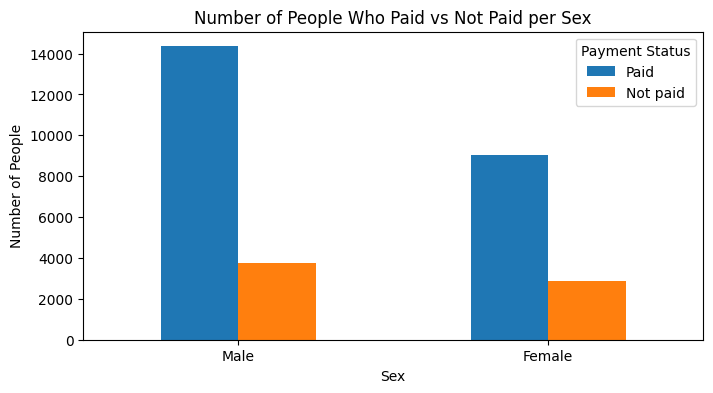

In [99]:
# One row per sex, one column per payment status
pivot = sex_df.pivot(index="SEX", columns="default.payment.next.month", values="Count")
pivot = pivot.loc[["Male", "Female"], ["Paid", "Not paid"]]

ax = pivot.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_title("Number of People Who Paid vs Not Paid per Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Number of People")
ax.legend(title="Payment Status")

plt.show()

In [100]:
df.groupby(["EDUCATION", "default.payment.next.month"]).count()["MARRIAGE"].reset_index().rename({"MARRIAGE": "Count"}, axis=1)

,EDUCATION,default.payment.next.month,Count
0,0,0,14
1,1,0,8549
2,1,1,2036
3,2,0,10700
4,2,1,3330
5,3,0,3680
6,3,1,1237
7,4,0,116
8,4,1,7
9,5,0,305


In [101]:
df.groupby(["MARRIAGE", "default.payment.next.month"]).count()["EDUCATION"].reset_index().rename({"EDUCATION": "Count"}, axis=1)

,MARRIAGE,default.payment.next.month,Count
0,0,0,49
1,0,1,5
2,1,0,10453
3,1,1,3206
4,2,0,12623
5,2,1,3341
6,3,0,239
7,3,1,84


In [102]:
px.histogram(df["LIMIT_BAL"])

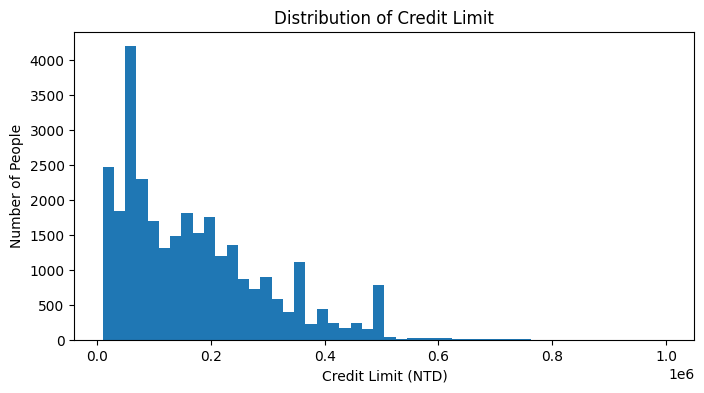

In [103]:
plt.figure(figsize=(8, 4))
plt.hist(df["LIMIT_BAL"], bins=50)
plt.title("Distribution of Credit Limit")
plt.xlabel("Credit Limit (NTD)")
plt.ylabel("Number of People")
plt.show()

In [104]:
fig = px.histogram(
    df,
    x="LIMIT_BAL",
    color="default.payment.next.month",
    barmode="group",
    title="Number of People Who Paid vs Not Paid per Limit",
    height=400,
        labels={
        "LIMIT_BAL": "Limit",
        "default.payment.next.month": "Payment Status"
    },
)
fig

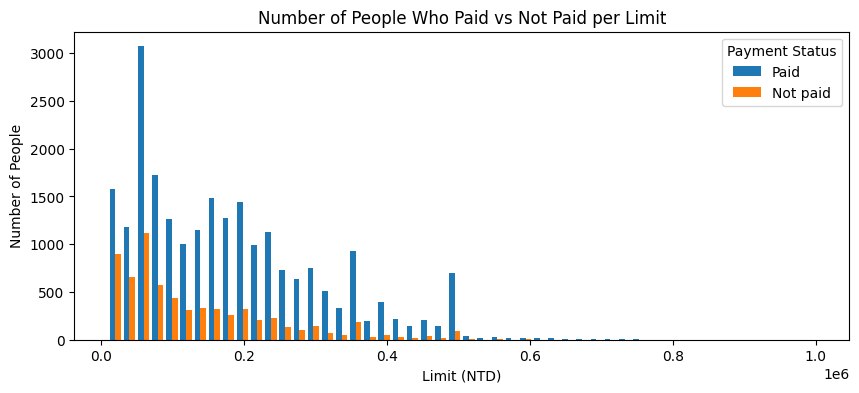

In [105]:
paid = df[df["default.payment.next.month"] == 0]["LIMIT_BAL"]
not_paid = df[df["default.payment.next.month"] == 1]["LIMIT_BAL"]

plt.figure(figsize=(10, 4))
plt.hist([paid, not_paid], bins=50, label=["Paid", "Not paid"])
plt.title("Number of People Who Paid vs Not Paid per Limit")
plt.xlabel("Limit (NTD)")
plt.ylabel("Number of People")
plt.legend(title="Payment Status")
plt.show()

In [106]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default.payment.next.month'],
      dtype='object')

In [107]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,1,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,1,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,1,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,1,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,0,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [108]:
# Total bill
# df["TOTAL BILL"] = df["BILL_AMT1"] + df["BILL_AMT2"] + df["BILL_AMT3"] + df["BILL_AMT4"] + df["BILL_AMT5"] + df["BILL_AMT6"] -> doesn't make sense. The last bill already carries how much the person currently owns
df["TOTAL PAID"] = df["PAY_AMT1"] + df["PAY_AMT2"] + df["PAY_AMT3"] + df["PAY_AMT4"] + df["PAY_AMT5"] + df["PAY_AMT6"]

# I literally just want to see these relationships with the target. I don't know yet if I'd keep them as a variables to help us predict.

In [109]:
# How much of the bill was paid:
((df["PAY_AMT1"] / df["BILL_AMT1"]).clip(0, 1) * 100).describe() # keeps the value between 0 and 1. Some customers paid more than the bill, and some bills are negative or 0, which gives strange values.

,0
count,28532.000000
mean,25.735314
std,36.158328
min,0.000000
25%,3.692949
50%,6.088743
75%,30.168364
max,100.000000


In [110]:
for i in range(1, 6):
      bill = df[f"BILL_AMT{i+1}"]
      pay = df[f"PAY_AMT{i}"]
      # If nothing was owed (bill <= 0), count it as fully paid
      df[f"paid_ratio_{i}_%"] = (pay / bill).where(bill > 0, 1).clip(0, 1) * 100

In [111]:
# Since dividing by 0 gives NaN, we can replace the NaNs for 1, because the BILL was 0 - therefore there was no bill we can consider was paid. I think.
df[["paid_ratio_1_%", "paid_ratio_2_%", "paid_ratio_3_%", "paid_ratio_4_%", "paid_ratio_5_%"]] = df[["paid_ratio_1_%", "paid_ratio_2_%", "paid_ratio_3_%", "paid_ratio_4_%", "paid_ratio_5_%"]].fillna(100)

In [112]:
df[["paid_ratio_1_%", "paid_ratio_2_%", "paid_ratio_3_%", "paid_ratio_4_%", "paid_ratio_5_%"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   paid_ratio_1_%  30000 non-null  float64
 1   paid_ratio_2_%  30000 non-null  float64
 2   paid_ratio_3_%  30000 non-null  float64
 3   paid_ratio_4_%  30000 non-null  float64
 4   paid_ratio_5_%  30000 non-null  float64
dtypes: float64(5)
memory usage: 1.1 MB


In [113]:
df[["paid_ratio_1_%", "paid_ratio_2_%", "paid_ratio_3_%", "paid_ratio_4_%", "paid_ratio_5_%"]].describe()

,paid_ratio_1_%,paid_ratio_2_%,paid_ratio_3_%,paid_ratio_4_%,paid_ratio_5_%
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,40.288740,41.191158,40.339961,40.320850,42.989506
std,43.997290,44.369957,44.777522,45.083002,45.552344
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.467446,4.460736,3.792314,3.639748,3.809166
50%,10.153543,10.375529,8.435207,7.695208,9.038762
75%,100.000000,100.000000,100.000000,100.000000,100.000000
max,100.000000,100.000000,100.000000,100.000000,100.000000


In [114]:
# On average, are the customers paying their full bills?
df[["paid_ratio_1_%", "paid_ratio_2_%", "paid_ratio_3_%", "paid_ratio_4_%", "paid_ratio_5_%"]].mean()

,0
paid_ratio_1_%,40.288740
paid_ratio_2_%,41.191158
paid_ratio_3_%,40.339961
paid_ratio_4_%,40.320850
paid_ratio_5_%,42.989506


In [115]:
# On average, are the default customers paying their full bills?
defaulted = df[df["default.payment.next.month"] == 1]
defaulted[["paid_ratio_1_%", "paid_ratio_2_%", "paid_ratio_3_%", "paid_ratio_4_%", "paid_ratio_5_%"]].mean()

,0
paid_ratio_1_%,31.687714
paid_ratio_2_%,32.657517
paid_ratio_3_%,32.093256
paid_ratio_4_%,33.114785
paid_ratio_5_%,35.662099


In [116]:
# How about the ones that paid?
not_defaulted = df[df["default.payment.next.month"] == 0]
not_defaulted[["paid_ratio_1_%", "paid_ratio_2_%", "paid_ratio_3_%", "paid_ratio_4_%", "paid_ratio_5_%"]].mean()

,0
paid_ratio_1_%,42.731661
paid_ratio_2_%,43.614940
paid_ratio_3_%,42.682246
paid_ratio_4_%,42.367565
paid_ratio_5_%,45.070685


In [117]:
# How much of the credit limit is being used -> there's no Limit = 0, so probably no NaNs
df["utilisation_1"] = df["BILL_AMT1"] / df["LIMIT_BAL"]
df["utilisation_2"] = df["BILL_AMT2"] / df["LIMIT_BAL"]
df["utilisation_3"] = df["BILL_AMT3"] / df["LIMIT_BAL"]
df["utilisation_4"] = df["BILL_AMT4"] / df["LIMIT_BAL"]
df["utilisation_5"] = df["BILL_AMT5"] / df["LIMIT_BAL"]
df["utilisation_6"] = df["BILL_AMT6"] / df["LIMIT_BAL"]

In [118]:
df["utilisation_1"].describe()

,utilisation_1
count,30000.000000
mean,0.423771
std,0.411462
min,-0.619892
25%,0.022032
50%,0.313994
75%,0.829843
max,6.455300


In [119]:
df[["utilisation_1", "utilisation_2", "utilisation_3", "utilisation_4", "utilisation_5", "utilisation_6"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   utilisation_1  30000 non-null  float64
 1   utilisation_2  30000 non-null  float64
 2   utilisation_3  30000 non-null  float64
 3   utilisation_4  30000 non-null  float64
 4   utilisation_5  30000 non-null  float64
 5   utilisation_6  30000 non-null  float64
dtypes: float64(6)
memory usage: 1.4 MB


In [120]:
df[["utilisation_1", "utilisation_2", "utilisation_3", "utilisation_4", "utilisation_5", "utilisation_6"]].head()

,utilisation_1,utilisation_2,utilisation_3,utilisation_4,utilisation_5,utilisation_6
0,0.195650,0.155100,0.034450,0.000000,0.000000,0.000000
1,0.022350,0.014375,0.022350,0.027267,0.028792,0.027175
2,0.324878,0.155856,0.150656,0.159233,0.166089,0.172767
3,0.939800,0.964660,0.985820,0.566280,0.579180,0.590940
4,0.172340,0.113400,0.716700,0.418800,0.382920,0.382620


In [121]:
cor = df.corr()
cor["default.payment.next.month"].sort_values()

,default.payment.next.month
LIMIT_BAL,-0.153520
paid_ratio_1_%,-0.104186
paid_ratio_2_%,-0.102502
TOTAL PAID,-0.102354
paid_ratio_3_%,-0.098154
paid_ratio_5_%,-0.085729
paid_ratio_4_%,-0.085187
PAY_AMT1,-0.072929
PAY_AMT2,-0.058579
PAY_AMT4,-0.056827


In [122]:
# Let's see if this new variables have a big correlation between the old ones and themselves
cor = cor[abs(cor["default.payment.next.month"]) > 0.1]
px.imshow(cor)

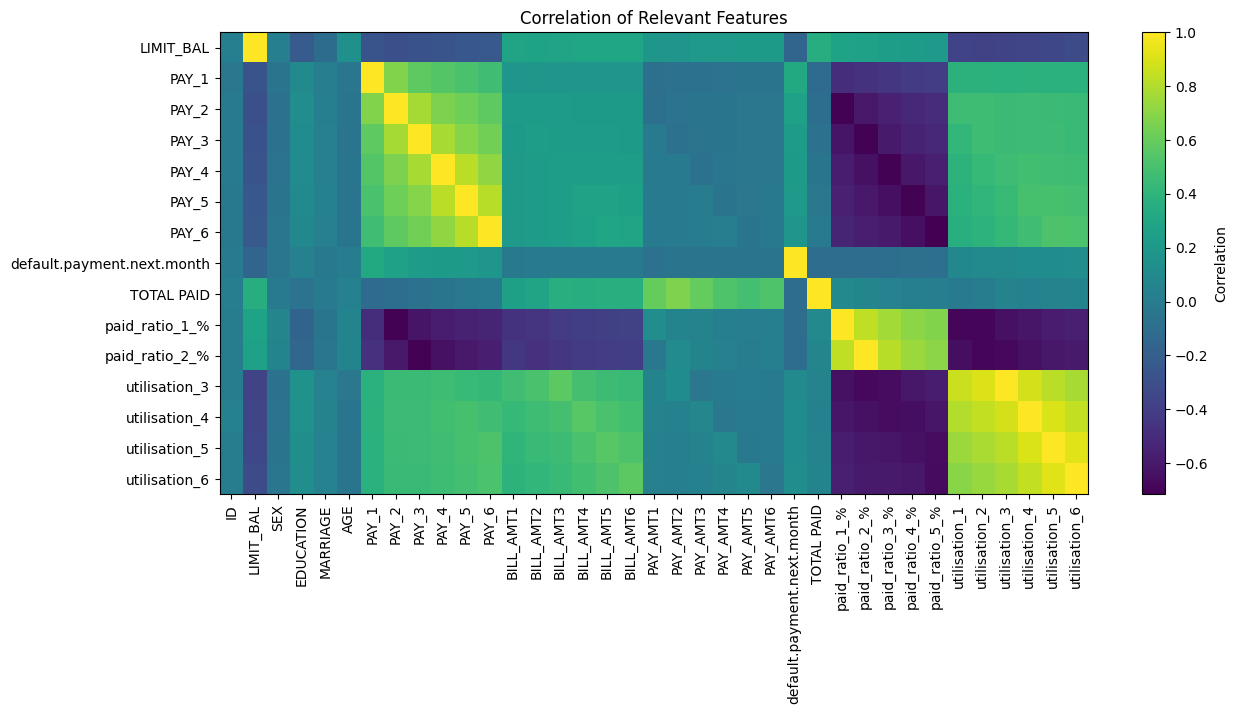

In [123]:
plt.figure(figsize=(14, 6))
plt.imshow(cor, cmap="viridis", aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(cor.columns)), cor.columns, rotation=90)
plt.yticks(range(len(cor.index)), cor.index)
plt.title("Correlation of Relevant Features")
plt.show()

Some variables have multicolinearity, which means that they are very correlated. If we were doing a Logistic Regression model, deleting them would be better, because they affect the coeficients and interpreting the results, even though they don't affect the predictions. It's just two columns carrying the same information basically. We will redo some stuff them because we will try Logistic Regression here.

In [124]:
# Let's replace all six utilization columns with their average. They are almost the same column, and the average keeps the information from all six months.
df["utilisation_avg"] = ((df["utilisation_1"] +  df["utilisation_2"] + df["utilisation_3"] + df["utilisation_4"] +  df["utilisation_5"] + df["utilisation_6"])/6)

# Same for paid_ratio
df["paid_ratio_avg"] = ((df["paid_ratio_1_%"] +  df["paid_ratio_2_%"] + df["paid_ratio_3_%"] + df["paid_ratio_4_%"] +  df["paid_ratio_5_%"])/5)

# We can remove PAY_AMT1 to PAY_AMT6 and keep only TOTAL_PAID, their sum
df.drop(["PAY_AMT1", "PAY_AMT2", "PAY_AMT3", "PAY_AMT4", "PAY_AMT5", "PAY_AMT6"], axis=1, inplace=True)

# Number of earlier months the customer was late (payment status of 1 or more)
df["months_late"] = (df[["PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]] > 0).sum(axis=1)

In [125]:
# Let's see if anything changed:
cor2 = df.corr()
cor2 = cor2[abs(cor2["default.payment.next.month"]) > 0.1]
px.imshow(cor2)

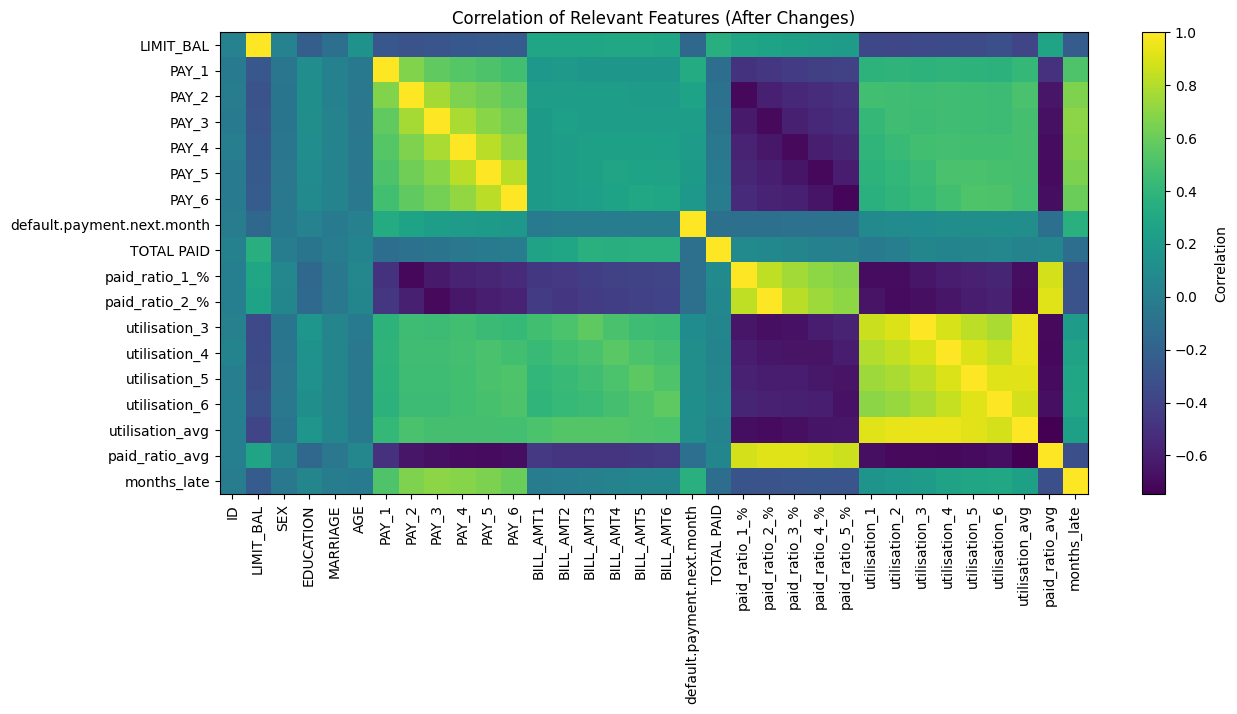

In [126]:
# Let's see if anything changed:
cor2 = df.corr()
cor2 = cor2[abs(cor2["default.payment.next.month"]) > 0.1]

plt.figure(figsize=(14, 6))
plt.imshow(cor2, cmap="viridis", aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(cor2.columns)), cor2.columns, rotation=90)
plt.yticks(range(len(cor2.index)), cor2.index)
plt.title("Correlation of Relevant Features (After Changes)")
plt.show()

In [127]:
# Months late has a high correlation, nice.
# Here we will delete all irrelevant variables, like ID
relevant_cols = cor[abs(cor["default.payment.next.month"]) > 0.1].index
prep = df[relevant_cols].copy()

In [128]:
prep.head()

,LIMIT_BAL,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,default.payment.next.month,TOTAL PAID,paid_ratio_1_%,paid_ratio_2_%,utilisation_3,utilisation_4,utilisation_5,utilisation_6
0,20000.0,2,2,-1,-1,-2,-2,1,689.0,0.000000,100.000000,0.034450,0.000000,0.000000,0.000000
1,120000.0,-1,2,0,0,0,2,1,5000.0,0.000000,37.285608,0.022350,0.027267,0.028792,0.027175
2,90000.0,0,0,0,0,0,0,0,11018.0,10.821986,11.062763,0.150656,0.159233,0.166089,0.172767
3,50000.0,0,0,0,0,0,0,0,8388.0,4.146539,4.096082,0.985820,0.566280,0.579180,0.590940
4,50000.0,-1,0,-1,0,0,0,0,59049.0,35.273369,100.000000,0.716700,0.418800,0.382920,0.382620


In [129]:
prep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   LIMIT_BAL                   30000 non-null  float64
 1   PAY_1                       30000 non-null  int64  
 2   PAY_2                       30000 non-null  int64  
 3   PAY_3                       30000 non-null  int64  
 4   PAY_4                       30000 non-null  int64  
 5   PAY_5                       30000 non-null  int64  
 6   PAY_6                       30000 non-null  int64  
 7   default.payment.next.month  30000 non-null  int64  
 8   TOTAL PAID                  30000 non-null  float64
 9   paid_ratio_1_%              30000 non-null  float64
 10  paid_ratio_2_%              30000 non-null  float64
 11  utilisation_3               30000 non-null  float64
 12  utilisation_4               30000 non-null  float64
 13  utilisation_5               300

In [130]:
# Change the numerical values that are actually categorical to categorical ones.

temp = df.copy()

# Education
ed_cat = pd.get_dummies(temp["EDUCATION"])
ed_cat = ed_cat.rename({0: "Education_0", 1: "Education_1", 2: "Education_2", 3: "Education_3", 4: "Education_4", 5: "Education_5"}, axis=1)

# Marriage
mar_cat = pd.get_dummies(temp["MARRIAGE"])
mar_cat = mar_cat.rename({0: "Marriage_0", 1: "Marriage_1", 2: "Marriage_2", 3: "Marriage_3", 4: "Marriage_4" }, axis=1)

In [131]:
df_temp = pd.merge(prep, ed_cat, right_index=True, left_index=True)
df_final = pd.merge(df_temp, mar_cat, right_index=True, left_index=True)

In [132]:
df_final.columns

Index(['LIMIT_BAL', 'PAY_1', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
       'default.payment.next.month', 'TOTAL PAID', 'paid_ratio_1_%',
       'paid_ratio_2_%', 'utilisation_3', 'utilisation_4', 'utilisation_5',
       'utilisation_6', 'Education_0', 'Education_1', 'Education_2',
       'Education_3', 'Education_4', 'Education_5', 'Marriage_0', 'Marriage_1',
       'Marriage_2', 'Marriage_3'],
      dtype='object')

In [133]:
df_final.head()

,LIMIT_BAL,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,default.payment.next.month,TOTAL PAID,paid_ratio_1_%,...,Education_0,Education_1,Education_2,Education_3,Education_4,Education_5,Marriage_0,Marriage_1,Marriage_2,Marriage_3
0,20000.0,2,2,-1,-1,-2,-2,1,689.0,0.000000,...,False,False,True,False,False,False,False,True,False,False
1,120000.0,-1,2,0,0,0,2,1,5000.0,0.000000,...,False,False,True,False,False,False,False,False,True,False
2,90000.0,0,0,0,0,0,0,0,11018.0,10.821986,...,False,False,True,False,False,False,False,False,True,False
3,50000.0,0,0,0,0,0,0,0,8388.0,4.146539,...,False,False,True,False,False,False,False,True,False,False
4,50000.0,-1,0,-1,0,0,0,0,59049.0,35.273369,...,False,False,True,False,False,False,False,True,False,False


In [134]:
# Let's see if anything changed with the categorical values:
cor3 = df_final.corr()
cor3 = cor3[abs(cor3["default.payment.next.month"]) > 0.1]
px.imshow(cor3)

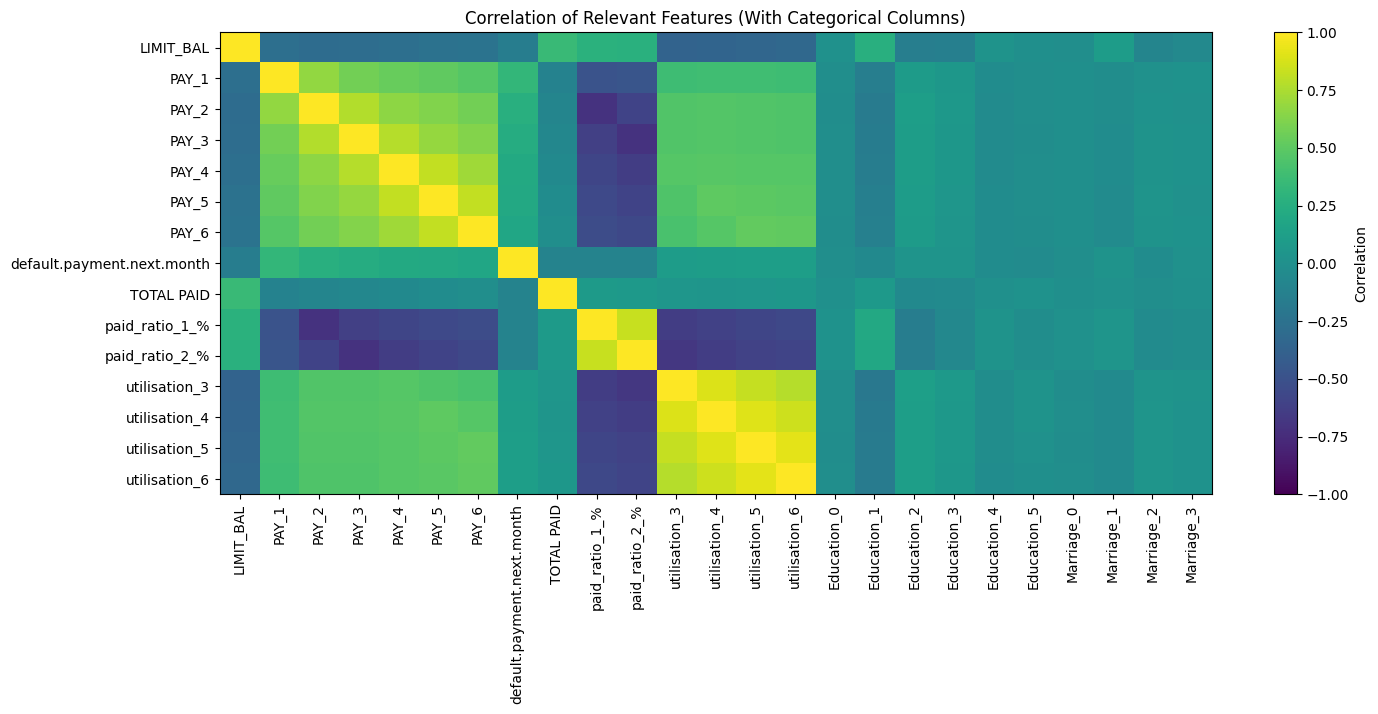

In [135]:
# Let's see if anything changed with the categorical values:
cor3 = df_final.corr()
cor3 = cor3[abs(cor3["default.payment.next.month"]) > 0.1]

plt.figure(figsize=(16, 6))
plt.imshow(cor3, cmap="viridis", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cor3.columns)), cor3.columns, rotation=90)
plt.yticks(range(len(cor3.index)), cor3.index)
plt.title("Correlation of Relevant Features (With Categorical Columns)")
plt.show()

Didn't change. Let's go with the previous dataset and later we can add more variables.

In [136]:
prep.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   LIMIT_BAL                   30000 non-null  float64
 1   PAY_1                       30000 non-null  int64  
 2   PAY_2                       30000 non-null  int64  
 3   PAY_3                       30000 non-null  int64  
 4   PAY_4                       30000 non-null  int64  
 5   PAY_5                       30000 non-null  int64  
 6   PAY_6                       30000 non-null  int64  
 7   default.payment.next.month  30000 non-null  int64  
 8   TOTAL PAID                  30000 non-null  float64
 9   paid_ratio_1_%              30000 non-null  float64
 10  paid_ratio_2_%              30000 non-null  float64
 11  utilisation_3               30000 non-null  float64
 12  utilisation_4               30000 non-null  float64
 13  utilisation_5               300

In [137]:
# First, let's see how the model would perform without any data preparation or cleaning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = df.drop(["ID", "default.payment.next.month"], axis=1)
y = df["default.payment.next.month"]

X = pd.get_dummies(X, columns=["EDUCATION", "MARRIAGE"], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.99      0.88      4673
           1       0.61      0.04      0.08      1327

    accuracy                           0.78      6000
   macro avg       0.70      0.52      0.48      6000
weighted avg       0.75      0.78      0.70      6000



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



In [138]:
print(confusion_matrix(y_test, y_pred))

[[4636   37]
 [1269   58]]


The baseline is bad for our case. The model is super careful and basically just predicts that the person will pay. The accuracy gives a false impression, because since most of our data is people that paid, the model did well in that. But the recall for 1 (defaulted) is only 0.04, which means that it predicted only 58 out of 1327 defaulted.

In [139]:
# With the data prep:

X = prep.drop(["default.payment.next.month"], axis=1)
y = prep["default.payment.next.month"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))
print("----")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.96      0.89      4673
           1       0.67      0.27      0.38      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.61      0.63      6000
weighted avg       0.79      0.81      0.78      6000

----
[[4500  173]
 [ 974  353]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



From 58 to 353, and the recall from 0.04 to 0.27. A significant improvement, but not as good as it needs to be yet.

The test had 6000 customers. 4673 paid and 1327 didn't.

The model said that 353 were not gonna pay out of the 1327, that's why recall for 1 is still low. It didn't do a good job. However, since precision is 67%, when the model says "this one will default", it's right 67% of the time. 526 (353 + 173) flagged as 1, 353 correct (67%).

The model almost always says "will pay". It's very cautious: it flags only the very obvious cases.

Accuracy 0.81 is misleading, as said before. Always guessing "pays" gives 4,673 / 6,000 = 0.78. So the model is only 3 points better than a model that always predicts 0.

The bank would miss 73% of the customers who default. As a risk tool, that's not useful yet.

Why it happens
Imbalance: only 22% default, so the model learns that "pays" is the safe guess.

In [140]:
# Let's try scaling things:

from sklearn.preprocessing import StandardScaler

X = prep.drop(["default.payment.next.month"], axis=1)
y = prep["default.payment.next.month"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=42, stratify=y)

# 3. Scale. Fit on train only, then apply the same scaling to test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# scale formula: scaled value = (value − mean) / std -> that's why we need the mean and std in fit_transform x transform

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_s, y_train)

y_pred = clf.predict(X_test_s)

print(classification_report(y_test, y_pred))
print("----")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.96      0.89      4673
           1       0.66      0.25      0.37      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.61      0.63      6000
weighted avg       0.78      0.81      0.77      6000

----
[[4499  174]
 [ 989  338]]


That’s a very small difference, so neither version is really better. Scaling isn’t meant to make Logistic Regression much more accurate anyway. It helps the model train properly and makes the coefficients comparable.

The simplest fix is to tell the model that defaulters matter more:

In [157]:
# With the data prep and balanced classes:

X = prep.drop(["default.payment.next.month"], axis=1)
y = prep["default.payment.next.month"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)

print(classification_report(y_test, y_pred))
print("----")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.80      0.83      4673
           1       0.44      0.57      0.50      1327

    accuracy                           0.75      6000
   macro avg       0.65      0.68      0.66      6000
weighted avg       0.77      0.75      0.76      6000

----
[[3719  954]
 [ 574  753]]


Way better. Recall moved to 0.57, 753 out of 1327 flagged correctly, but the precision dropped. I decided to keep the Scaler because it changed the model for worse (recall)just a few and at least now we can analyse the coefficients.

Let's analyse the coefficents:

In [142]:
# Coefficients
import numpy

coefs = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_[0]})
coefs["Exp(Coef)"] = numpy.exp(coefs["Coefficient"])
coefs = coefs.sort_values("Coefficient", ascending=False)
coefs

,Feature,Coefficient,Exp(Coef)
1,PAY_1,0.589302,1.802730
8,paid_ratio_1_%,0.355118,1.426349
9,paid_ratio_2_%,0.296434,1.345054
2,PAY_2,0.254053,1.289240
3,PAY_3,0.224531,1.251735
13,utilisation_6,0.135999,1.145680
10,utilisation_3,0.120147,1.127662
4,PAY_4,0.073788,1.076579
6,PAY_6,0.036876,1.037564
11,utilisation_4,0.029694,1.030140


Each coefficient tells us how a feature moves the risk of default, assuming the other features stay the same:

- Positive: a higher value means more likely to default.
- Negative: a higher value means less likely to default.

The model was trained on scaled features, so each coefficient shows the effect of a 1 standard deviation increase in that feature, assuming the others stay the same. This means the sizes can be compared: the further from 0, the stronger the feature. Exp(Coef) above 1 means higher risk of default; below 1 means lower risk.

**1. Recent payment status is the strongest warning sign.**
- `PAY_1` (September) has the biggest effect of all features: a 1 standard deviation increase (about one more month of delay) raises the odds of default by about **80%**.
- August (`PAY_2`, +29%) and July (`PAY_3`, +25%) also matter. The older months (`PAY_4` to `PAY_6`) add only 3–8%.
- So what a customer did last month matters much more than what they did half a year ago.

**2. Paying more lowers the risk the most.**
- `TOTAL PAID` is the strongest protective feature: a 1 standard deviation increase lowers the odds of default by about **27%**.
- `LIMIT_BAL`: a limit about 130,000 NTD higher (1 standard deviation) lowers the odds by about **12%**. Banks usually give higher limits to customers they already trust, so this partly reflects the bank's own assessment.

**3. High utilisation raises the risk, but the individual months should not be read alone.**
- Most utilisation features are positive (+3% to +15%), but `utilisation_5` is negative (-11%).
- These four columns are 80–90% correlated, so the model splits the effect between them in an unstable way. Read together, they show that customers who keep their card close to the limit are more likely to default.

**4. The paid ratio result is not reliable.**
- `paid_ratio_1_%` (+43%) and `paid_ratio_2_%` (+35%) are the second and third strongest features, and both point to higher risk. Taken literally, this would mean paying a larger share of the bill makes default more likely.
- On its own, the paid ratio has a negative correlation with default, as expected. The sign flips here because it overlaps heavily with payment status (correlation around -0.7). Once the model knows the payment status, it uses the paid ratio to correct for that overlap rather than as a signal of its own.


In [143]:
# Changing the threshold might help us:
probs = model.predict_proba(X_test_s)[:, 1]
y_pred_09 = (probs > 0.5).astype(int)

In [144]:
print(confusion_matrix(y_test, y_pred_09))

[[3719  954]
 [ 574  753]]


In [145]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_09).ravel()

print(tp)

753


Let's get the ideal threshold for this case:

In [146]:
prob = 100
p = 1
probs = []
temp = model.predict_proba(X_test_s)[:, 1]

for p in range(prob):
  y_temp_pred = (temp > float(p/100)).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_test, y_temp_pred).ravel()
  probs.append(tp)
  p += 1

In [147]:
px.line(probs)

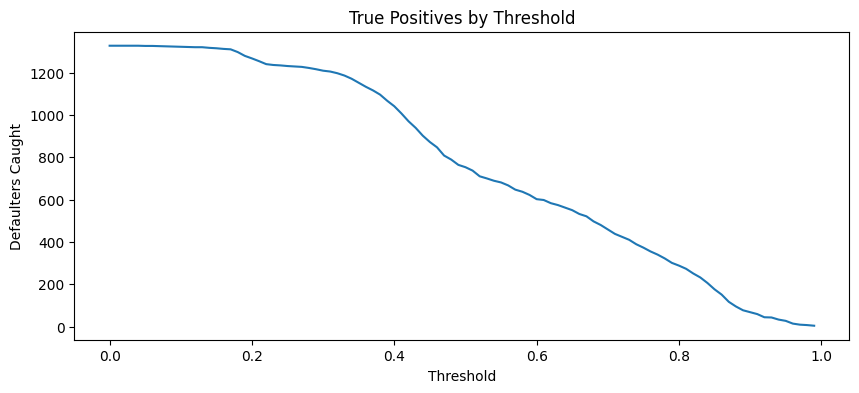

In [148]:
thresholds = [p / 100 for p in range(len(probs))]

plt.figure(figsize=(10, 4))
plt.plot(thresholds, probs)
plt.title("True Positives by Threshold")
plt.xlabel("Threshold")
plt.ylabel("Defaulters Caught")
plt.show()

We need to compare the precision as well, to see how many 'defaulted' are being scored as well.



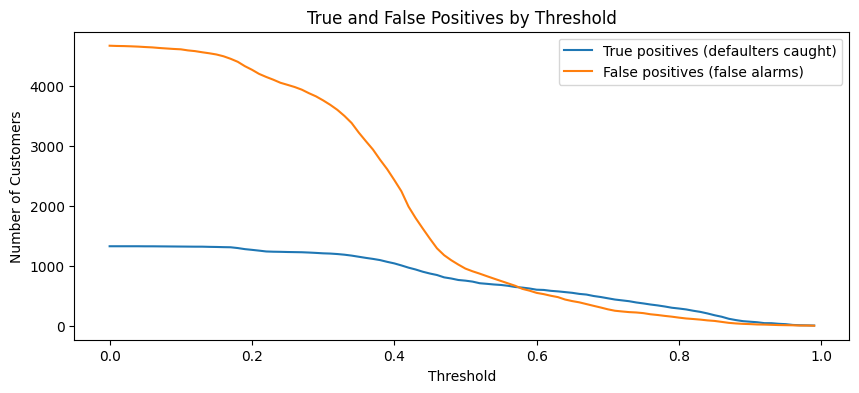

In [149]:
temp = model.predict_proba(X_test_s)[:, 1]
results = []

for p in range(100):
    threshold = p / 100
    y_temp_pred = (temp > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_temp_pred).ravel()
    results.append({"threshold": threshold, "true_positives": tp, "false_positives": fp})

results = pd.DataFrame(results)

plt.figure(figsize=(10, 4))
plt.plot(results["threshold"], results["true_positives"], label="True positives (defaulters caught)")
plt.plot(results["threshold"], results["false_positives"], label="False positives (false alarms)")
plt.title("True and False Positives by Threshold")
plt.xlabel("Threshold")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

1. Below 0.3: the model flags almost everyone.

We catch almost all 1,327 defaulters, but you also send 3,700–4,700 false alarms.
That’s almost no better than flagging every customer, so it isn’t useful.

2. Between 0.3 and 0.5: this is where the model really works.

False alarms fall sharply, from about 3,700 to about 950.
Defaulters caught only fall from about 1,200 to about 750.
So in this range, raising the threshold removes many false alarms while losing only a few defaulters. Each step up is a good trade.

3. Above 0.5: both lines fall slowly together.

Now every bit of threshold we add costs defaulters at about the same rate as it removes false alarms.
The lines cross at about 0.57. Above that point, more than half of the flagged customers are real defaulters.

Around 0.45–0.5 is a good starting point. At 0.5, we catch about 750 defaulters (around 57% recall) with about 950 false alarms (around 44% precision).
Go lower (around 0.4) if missing a defaulter is very expensive and a false alarm is cheap, for example if the action is just a reminder message. We'd catch about 1,000 defaulters, but with about 2,300 false alarms.
Go higher (around 0.6 or more) if the action is costly or annoys good customers, like lowering their credit limit. We’d get fewer false alarms, but we’d miss more defaulters.

Why 0.5 works here: the model was trained with class_weight="balanced", which already pushes the model’s probabilities up for defaulters. So the default threshold of 0.5 is already more “alert” than it would be without the balancing.

To choose exactly: the best threshold depends on what each mistake costs the bank. If we give a cost to a missed defaulter and a cost to a false alarm, you can calculate the total cost for each threshold and pick the lowest.

But for now, let's try another algorithm.

In [150]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

X = prep.drop(["default.payment.next.month"], axis=1)
y = prep["default.payment.next.month"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

knn_model = KNeighborsClassifier(weights="distance").fit(X_train_s, y_train)

y_pred = knn_model.predict(X_test_s)

print(confusion_matrix(y_test, y_pred))
print("--")
print(classification_report(y_test, y_pred))

[[4240  433]
 [ 818  509]]
--
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      4673
           1       0.54      0.38      0.45      1327

    accuracy                           0.79      6000
   macro avg       0.69      0.65      0.66      6000
weighted avg       0.77      0.79      0.78      6000



Not as good as the Logistic Regression one. Let's check the ideal number of neighbours.

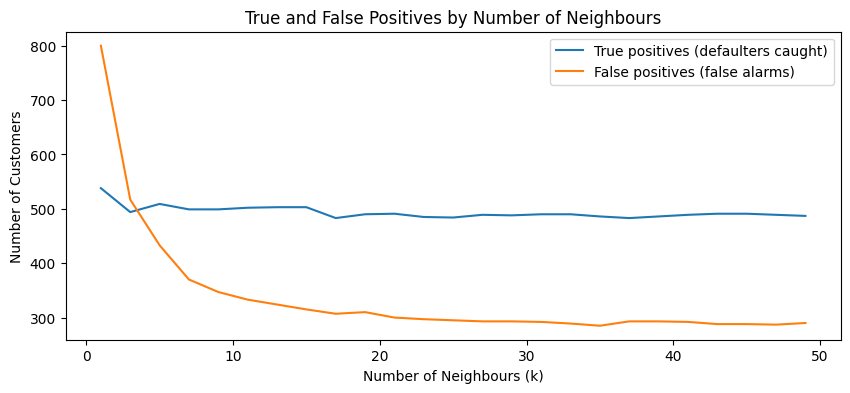

In [151]:
results = []

for k in range(1,50, 2):
    knn = KNeighborsClassifier(n_neighbors=k, weights="distance").fit(X_train_s, y_train)
    pred_i = knn.predict(X_test_s)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_i).ravel()
    results.append({"k": k, "true_positives": tp, "false_positives": fp})

results = pd.DataFrame(results)

plt.figure(figsize=(10, 4))
plt.plot(results["k"], results["true_positives"], label="True positives (defaulters caught)")
plt.plot(results["k"], results["false_positives"], label="False positives (false alarms)")
plt.title("True and False Positives by Number of Neighbours")
plt.xlabel("Number of Neighbours (k)")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

KNN predicts a customer by looking at the k most similar customers in the training data and taking a vote. If most of those neighbours defaulted, it predicts “will default”. So changing k changes who gets a vote, and that changes the prediction.

- Small k (like 1 or 3): the model listens to very few customers.

One unusual neighbour can decide the prediction, so the model reacts to noise. This is overfitting.
It flags more defaulters, but with more mistakes.

- Large k (like 30 or more): the model listens to many customers.

Predictions become smoother and more stable.
But because only 22% of customers default, a large group of neighbours is almost always mostly “paid”. So the model rarely flags anyone, and recall drops.

- Odd vs even k: this explains the zigzag in the chart.

With an even k, the vote can tie (for example 5 vs 5 with k = 10). Scikit-learn breaks ties by picking the first class, which is 0 (“paid”).
So even values of k flag fewer defaulters, so that's why for a two-class problem like this, we used odd values of k only.

Also, the imbalance is the main reason k matters so much. The bigger k gets, the more the majority class (“paid”) wins the vote. That's why we used weights="distance", which makes closer neighbours count more than farther ones, so the vote doesn’t depend only on the count.

What happens as k increases:

Defaulters caught stay almost flat: about 540 at k = 1, then between 485 and 510 for every other k.
False alarms fall a lot at first: from about 800 at k = 1, to about 370 at k = 7, to about 315 at k = 15. After about k = 20, they level off around 290–300.

What to conclude:

1. Raising k up to about 15–20 is almost free. False alarms drop by more than half while we lose only a few defaulters. Each extra neighbour removes noise without hurting what the model catches.

2. After about k = 20, nothing changes. Both lines are flat, so adding more neighbours only makes the model slower.

3. Best choice: k around 15. It catches about 500 defaulters (recall about 38%) with about 315 false alarms (precision about 61%). k = 21 is just as good: slightly fewer false alarms, slightly fewer defaulters caught.

4. Distance weights didn’t change the results much. Compared with our previous chart, the numbers at k = 13–15 are almost the same (about 500 caught, about 300 false alarms). Distance weights mainly removed the jumps.

5. The real limit is recall, not k. Whatever k we choose, KNN catches at most about 38% of defaulters. Changing k mostly changes the false alarms. To catch more defaulters, we could lower the decision threshold.

This chart uses the test set to choose k. For the final version, I would choose k with cross-validation on the training data, then report the test results once.

All that being said, Logistic Regression is still the best option.

Last algorithm to try: Decision Tree.

In [159]:
from sklearn.tree import DecisionTreeClassifier

X = prep.drop(["default.payment.next.month"], axis=1)
y = prep["default.payment.next.month"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Not tunned
tree_model = DecisionTreeClassifier().fit(X_train, y_train)

y_pred = tree_model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.83      0.83      4673
           1       0.39      0.38      0.38      1327

    accuracy                           0.73      6000
   macro avg       0.61      0.60      0.61      6000
weighted avg       0.73      0.73      0.73      6000



In [154]:
# from sklearn.model_selection import GridSearchCV

# param_grid = {
#     'max_depth': range(1, 10, 1),
#     'min_samples_leaf': range(1, 20, 2),
#     'min_samples_split': range(2, 20, 2),
#     'criterion': ["entropy", "gini"]
# }

# tree = DecisionTreeClassifier(random_state=1)

# grid_search = GridSearchCV(estimator=tree, param_grid=param_grid,
#                            cv=5, verbose=True)
# grid_search.fit(X_train, y_train)

# print("best accuracy", grid_search.best_score_)
# print(grid_search.best_estimator_)

Fitting 5 folds for each of 1620 candidates, totalling 8100 fits
best accuracy 0.8204166666666666
DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=1)

In [ ]:
# from sklearn.tree import plot_tree
# import matplotlib.pyplot as plt

# tree_clf = grid_search.best_estimator_

# plt.figure(figsize=(18, 15))
# plot_tree(tree_clf, filled=True, feature_names=X.columns,
#           class_names=X.columns)
# plt.show()

In [160]:
# Let's add class weights as well to add weights in the 'not going to pay class' bigger than 'pay' because of imbalance

X = prep.drop(["default.payment.next.month"], axis=1)
y = prep["default.payment.next.month"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# tunned
model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=1, class_weight="balanced").fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.84      0.86      4673
           1       0.50      0.55      0.52      1327

    accuracy                           0.78      6000
   macro avg       0.68      0.70      0.69      6000
weighted avg       0.79      0.78      0.78      6000



In [161]:
model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=1).fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.67      0.35      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.67      6000
weighted avg       0.80      0.82      0.79      6000

